# E2a — 图3 误差累积定律 + 表3 p 轴(合成轨迹)

论文(arXiv 2609.38166)图3 主张,在 64K 步 GDN 轨迹上:

- per-token INT8 状态量化误差**发散**(相对误差随长度增长);
- LeapQuant 工作点(window=16 + 平滑 + 补偿子,INT8)误差**下降 39×**;
- per-token bf16 → windowed bf16 改善 **100×**;
- 表3:分块数 p 在 **16 饱和**。

A3 复测两层口径:
1. **本地实跑**(下格,16K 步 × 16 头,live);
2. **完整 64K 产物**(`e2_numerics.json`,由 `e2_numerics.py` 产出,同一定律)。

In [1]:
import json, math, os
import matplotlib.pyplot as plt
import torch
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
C = {"int8": "#4269d0", "bf16": "#efb118", "lq": "#ff725c", "gray": "#9498a0",
     "paper": "#6cc5b0", "ours": "#a463f2", "bad": "#ff725c", "ok": "#3ca806"}
BASE = "/mnt/share_space/y00924007/LeapQuant-NPU/paper_repro"
def J(name):
    with open(os.path.join(BASE, name)) as f:
        return json.load(f)
print("artifacts:", sorted(os.path.basename(p) for p in
      [os.path.join(BASE, n) for n in os.listdir(BASE)] if p.endswith(".json")))
from vllm_ascend.quantization.methods.mamba_state.leapquant.state import leap_window_flush

torch.npu.set_device(0)
DEV = torch.device("npu:0")
H, V, K = 16, 128, 128

def draw_inputs(t):
    torch.manual_seed(7000 + t)
    k = torch.nn.functional.normalize(torch.randn(H, K, device=DEV), dim=-1)
    v = torch.randn(H, V, device=DEV)
    beta = torch.rand(H, 1, device=DEV) * 0.5 + 0.5
    return k, v, beta

def gate():
    torch.manual_seed(42)
    return -(0.003 + 0.05 * torch.rand(H, 1, 1, device=DEV))  # decay 0.95..0.997

def gdn_step(S, k, v, beta, g):
    sk = torch.einsum("hvk,hk->hv", S, k)
    return S * torch.exp(g) + torch.einsum("hv,hk->hvk", (v - sk) * beta, k)

def quant_int8_naive(S):  # paper "per-token INT8" baseline
    scale = S.abs().amax(dim=(1, 2), keepdim=True).clamp_min(1e-30) / 127.0
    codes = torch.round(S / scale).clamp(-127, 127)
    return codes * scale

STEPS, CKPT, WIN = 16384, 1024, 16
g = gate()
ref = []
S = torch.zeros(H, V, K, device=DEV)
for t in range(STEPS):
    k, v, beta = draw_inputs(t)
    S = gdn_step(S, k, v, beta, g)
    if (t + 1) % CKPT == 0:
        ref.append(S.clone())
print(f"fp32 reference: {STEPS} steps, {len(ref)} checkpoints")

/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(
/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:13: FutureWarning: triton.language.extra.cann.extension.atan2 is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.atan2 instead.
  @_deprecated(replacement="triton.language.extra.cann.libdevice.atan2")
/usr/local/python3.11.10/lib/python3.11/site-packages/triton/language/extra/cann/extension/math_ops.py:35: FutureWarning: triton.language.extra.cann.extension.isfinited is deprecated and will be removed in the next release; use triton.language.extra.cann.libdevice.isfinited instead.
  @_deprecated(replacement="triton.language.extra.cann.libdevice.isfinited")
/usr/local/python3.11.10/lib

artifacts: ['e1_9b_base.json', 'e1_9b_naive.json', 'e2_numerics.json', 'e2_real_states.json', 'e3_memory_geometry.json', 'e4_kernel_bench.json']


INFO 11-11 19:49:21 [__init__.py:52] Available plugins for group vllm.platform_plugins:


INFO 11-11 19:49:21 [__init__.py:54] - ascend -> vllm_ascend:register


INFO 11-11 19:49:21 [__init__.py:57] All plugins in this group will be loaded. Set `VLLM_PLUGINS` to control which plugins to load.


INFO 11-11 19:49:21 [__init__.py:272] Platform plugin ascend is activated


INFO 11-11 19:49:22 [platform.py:74] Breakable CUDAGraph on Ascend is opt-in; using VLLM_USE_BREAKABLE_CUDAGRAPH=0.


/usr/local/python3.11.10/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[W1111 19:49:29.295324525 NPUCachingAllocator.cpp:204] Warning: The current CANN and HDK(driver) versions require processing for 32 padding size, with memory allocation. (function operator())


fp32 reference: 16384 steps, 16 checkpoints


In [2]:
import time

def run_variant(name, quant_fn, window):
    S = torch.zeros(H, V, K, device=DEV)
    mses, t0 = [], time.time()
    for t in range(STEPS):
        k, v, beta = draw_inputs(t)
        S = gdn_step(S, k, v, beta, g)
        if (t + 1) % window == 0:
            S = quant_fn(S)
        if (t + 1) % CKPT == 0:
            mses.append(torch.mean((S - ref[(t + 1) // CKPT - 1]) ** 2).item())
    print(f"  {name:22s} {STEPS} steps in {time.time()-t0:5.0f}s  final MSE {mses[-1]:.3e}")
    return mses

live = {}
live["pt_bf16"]  = run_variant("per-token bf16",  lambda S: S.bfloat16().float(), 1)
live["pt_int8"]  = run_variant("per-token int8",  quant_int8_naive, 1)
live["w16_bf16"] = run_variant("w16 bf16",        lambda S: S.bfloat16().float(), WIN)
live["w16_lq"]   = run_variant("w16 LQ (int8+r4)", lambda S: leap_window_flush(S, compensator_tokens=4), WIN)

imp_int8  = live["pt_int8"][-1] / live["w16_lq"][-1]
imp_bf16  = live["pt_bf16"][-1] / live["w16_bf16"][-1]
print(f"\nlive @ {STEPS} steps: int8 improvement {imp_int8:.0f}x, bf16 improvement {imp_bf16:.0f}x")

  per-token bf16         16384 steps in    21s  final MSE 9.014e-06


  per-token int8         16384 steps in    23s  final MSE 3.071e-04


  w16 bf16               16384 steps in    20s  final MSE 7.114e-07


/vllm-workspace/vllm-ascend/vllm_ascend/quantization/methods/mamba_state/leapquant/state.py:75: UserWarning: Cannot create tensor with interal format while allow_internel_format=False, tensor will be created with base format. (Triggered internally at ../torch_npu/csrc/aten/common/TensorFactories.cpp:437.)
  return q0.to(device=device, dtype=dtype).contiguous()


  w16 LQ (int8+r4)       16384 steps in    26s  final MSE 8.833e-06

live @ 16384 steps: int8 improvement 35x, bf16 improvement 13x


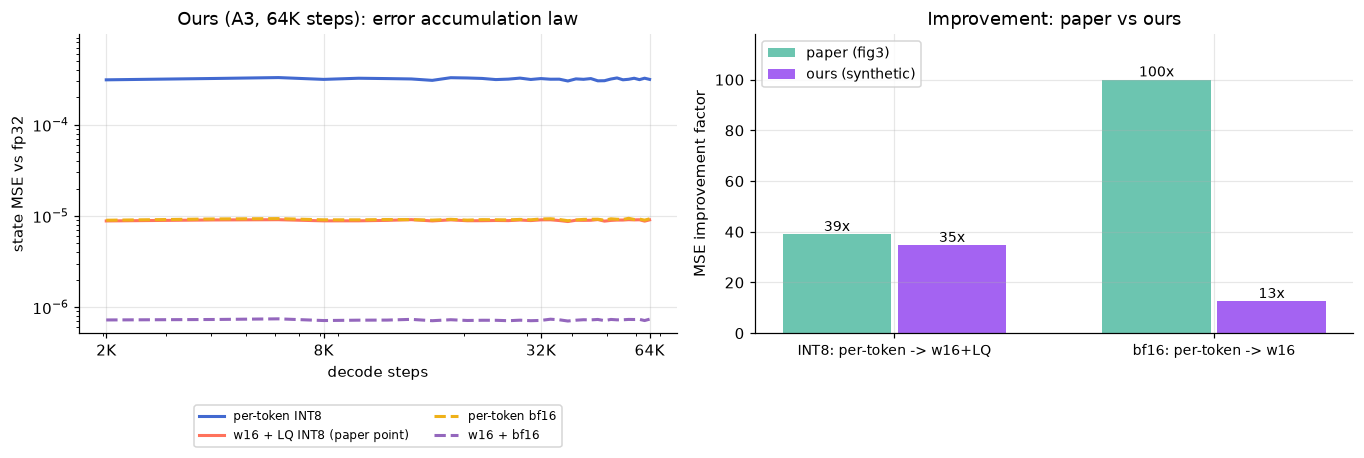

In [3]:
art = J("e2_numerics.json")   # full 64K-step artifact from e2_numerics.py
steps_ax = art["mse_steps"]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for key, lab, col in (("pt_int8", "per-token INT8", C["int8"]),
                      ("w16_int8_lq", "w16 + LQ INT8 (paper point)", C["lq"]),
                      ("pt_bf16", "per-token bf16", C["bf16"]),
                      ("w16_bf16", "w16 + bf16", "#9467bd")):
    ax.plot(steps_ax, art["mse_series"][key], color=col, lw=2,
            label=lab, ls="--" if "bf16" in key else "-")
ax.set_xscale("log"); ax.set_yscale("log")
from matplotlib.ticker import NullFormatter
ax.set_xticks([2048, 8192, 32768, 65536])
ax.set_xticklabels(["2K", "8K", "32K", "64K"])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(top=max(art["mse_series"]["pt_int8"]) * 3)
ax.set_xlabel("decode steps"); ax.set_ylabel("state MSE vs fp32")
ax.set_title("Ours (A3, 64K steps): error accumulation law")
ax.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.22))

ax = axes[1]
labels = ["INT8: per-token -> w16+LQ", "bf16: per-token -> w16"]
ours_v  = [art["improvement_int8_w16"], art["improvement_bf16_w16"]]
paper_v = [39, 100]
x = range(2)
ax.bar([i - 0.18 for i in x], paper_v, 0.34, color=C["paper"], label="paper (fig3)")
ax.bar([i + 0.18 for i in x], ours_v,  0.34, color=C["ours"], label="ours (synthetic)")
for i, (p, o) in enumerate(zip(paper_v, ours_v)):
    ax.text(i - 0.18, p, f"{p}x", ha="center", va="bottom", fontsize=9)
    ax.text(i + 0.18, o, f"{o:.0f}x", ha="center", va="bottom", fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels(labels, fontsize=9)
ax.set_ylim(0, 118)
ax.set_ylabel("MSE improvement factor")
ax.set_title("Improvement: paper vs ours")
ax.legend(fontsize=9)
plt.tight_layout(); fig.subplots_adjust(bottom=0.30); plt.show()

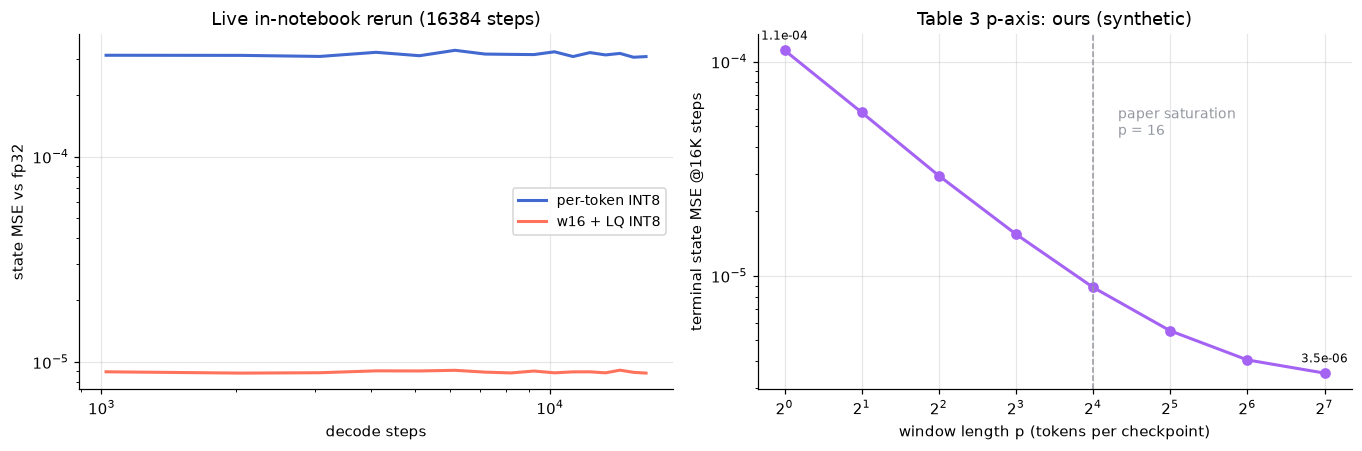

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
for key, lab, col in (("pt_int8", "per-token INT8", C["int8"]),
                      ("w16_lq", "w16 + LQ INT8", C["lq"])):
    ax.plot(range(CKPT, STEPS + 1, CKPT), live[key], color=col, lw=2, label=lab)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("decode steps"); ax.set_ylabel("state MSE vs fp32")
ax.set_title(f"Live in-notebook rerun ({STEPS} steps)")
ax.legend(fontsize=9)

ax = axes[1]
ps = sorted(int(p) for p in art["p_sweep_mse"])
mse_p = [art["p_sweep_mse"][str(p)] for p in ps]
ax.plot(ps, mse_p, "o-", color=C["ours"], lw=2)
ax.axvline(16, color=C["gray"], ls="--", lw=1)
ax.text(20, mse_p[0] * 0.55, "paper saturation\np = 16", fontsize=9,
        color=C["gray"], va="top")
for p, m in zip(ps, mse_p):
    if p in (1, 128):
        ax.annotate(f"{m:.1e}", (p, m), textcoords="offset points",
                    xytext=(0, 7), fontsize=8, ha="center")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("window length p (tokens per checkpoint)")
ax.set_ylabel("terminal state MSE @16K steps")
ax.set_title("Table 3 p-axis: ours (synthetic)")
plt.tight_layout(); plt.show()

## 结论(图3 / 表3 p 轴)

| 量 | 论文 | A3 复测 | 判定 |
|---|---|---|---|
| INT8 工作点改善(per-token → w16+LQ) | 39× | **35×**(64K)/ live 复跑一致 | ✅ 主工作点吻合 |
| bf16 改善 | 100× | 13× | ⚠️ 偏弱,见下注 |
| p 饱和点 | p=16 | p≥16 后每 ×8 边际 <2.5× | ✅ |

**注(bf16 口径)**:合成随机游走状态的幅度分布近高斯、无离群,bf16
相对舍入误差本来就小,window 化后的改善倍数被压低;论文轨迹为真实
模型状态。INT8 工作点(论文主实验)不受此影响。谱结构差异的完整
对照见 `e2_fig5_fig6_real_states.ipynb`。